# Self-RAG

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 근거 하나를 두고 두 글의 근거 점수를 재어 눈금을 봅니다.
3. 그 눈금을 보고 근거 점수 기준값과 고쳐 쓰기 상한을 정합니다.
4. 자료의 질문 하나를 검색해 앞 세 문서를 근거로 답 초안을 만듭니다.
5. 원문에 없는 문장을 일부러 붙인 답의 근거 점수를 받습니다.
6. 점수가 기준값보다 작으면 그 답을 한 번만 고쳐 씁니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 아홉 번이고 임베딩 두 번과 답 모델 일곱 번입니다.
점수가 기준값보다 작은 갈래에서는 답 모델을 세 번 부르고 크거나 같은 갈래에서는 한 번 부릅니다.
예상 비용은 미화 0.01달러 아래이고 읽어 오는 파일은 문서 파일과 질문 파일 둘입니다.
새로 쓰는 파일은 없고 실행 시간은 2분 안팎입니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3과 도구 파일이 쓰는 numpy 2.5.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절부터 10절까지 읽습니다.
Ch 12 검색 부품을 준비하고 점수 눈금을 보고 기준값을 정하는 자리입니다.
11절부터 14절까지는 답을 만들고 검사하고 한 번 고쳐 쓰는 자리입니다.
15절부터 17절까지는 검사할 답을 바꿔 보고 세 실행을 표로 보는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

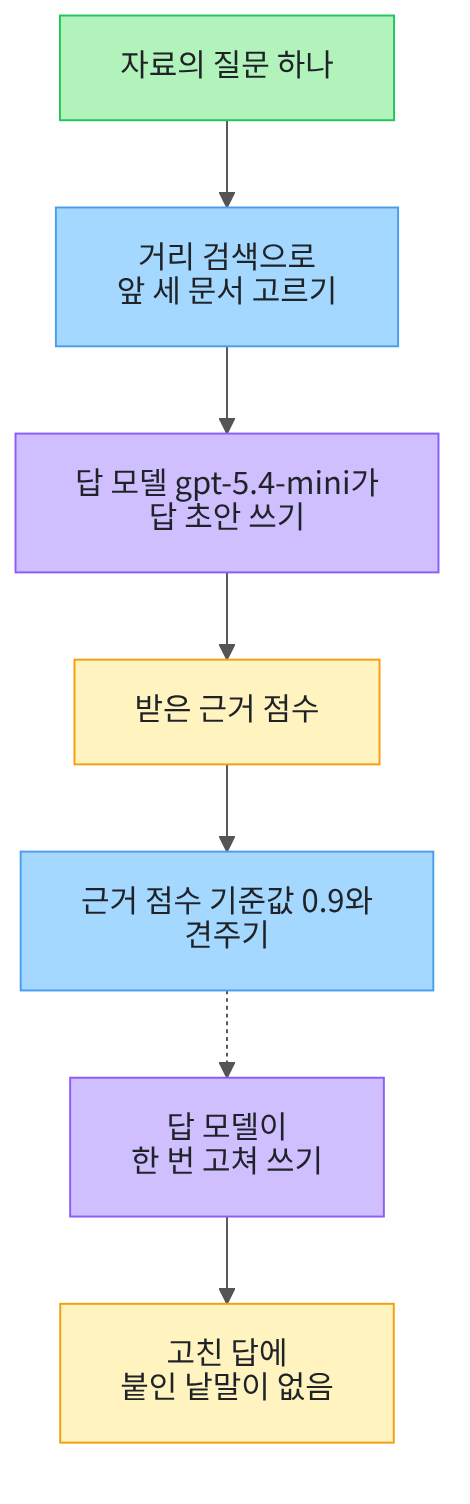

위에서 아래로 읽습니다.
맨 위 초록 상자가 자료에 있는 질문입니다.
파란 상자 둘이 우리가 적은 처리와 판정 규칙이고 보라 상자 둘이 모델입니다.
노란 상자 둘이 출력으로 확인한 값입니다.
점선은 점수가 기준값보다 작을 때만 가는 자리입니다.

## 1. 준비

첫 셀은 패키지 네 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "numpy==2.5.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 판 번호 네 줄이 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이름 네 개를 불러오고 도구 파일에서 함수 일곱 개를 가져옵니다.
앞의 둘은 자료 읽기와 폴더 확인에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 Ch 12 01절 `rank_by_distance()`와 05절 `print_ranked()`를 가져옵니다.
Ch 11 01절 `unique_doc_ids()`·`find_gold_rank()`와 02절 `split_lines()`도 가져옵니다.
01절에서 만든 `keeps_word()`와 `build_answer_prompt()`도 함께 가져옵니다.
인자 모양은 쓰는 자리에서 설명합니다.

In [2]:
# 자료 읽기·폴더 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model
# Ch 12 01·05절·Ch 11 01절 함수와 01·02절 함수를 도구 파일에서 가져옵니다
from rag_tools import build_answer_prompt, find_gold_rank, keeps_word, print_ranked
from rag_tools import rank_by_distance, split_lines, unique_doc_ids

print("불러온 이름:", "json", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 네 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 06절에서 쓴 것과 같습니다.
도구 파일에서 가져온 함수 일곱 개는 출력하지 않습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01~06절과 같은 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
Ch 10~13과 01~06절에서 쓴 방법과 같습니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
문서는 도서관 안내 열두 건입니다.

질문 번호는 C01부터 C08까지이고 질문 파일에 적혀 있습니다.
이 절은 그 가운데 하나를 골라 답까지 만듭니다.

## 4. 앞 절 부품 준비

다음 두 셀은 01~06절에서 이미 본 준비입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
첫 셀은 Ch 12에서 정한 값 둘을 그대로 적고 문서 글을 이어 붙입니다.
둘째 셀은 문서 ID로 원문을 찾을 짝을 만듭니다.
함수는 준비 셀에서 도구 파일로 가져왔습니다.

In [7]:
# Ch 12에서 쓴 값 둘을 그대로 적고 문서 12개의 제목과 본문을 이어 붙입니다
top_three = 3
top_all = 12
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])

나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.


In [8]:
# 문서 ID로 원문을 찾을 짝을 만듭니다(답 만들기와 근거 글에 원문을 넣으려고 씁니다)
text_by_doc = {}
for i in range(len(doc_ids)):
    text_by_doc[doc_ids[i]] = doc_texts[i]
print("짝의 수:", len(text_by_doc))

짝의 수: 12


준비 셀 두 개를 지났습니다.
02·03절이 쓴 순위 합치기 함수는 04~06절에 이어 이 절에서도 가져오지 않았습니다.
이 절도 목록 여러 개를 하나로 합치지 않기 때문입니다.
06절 검색 묶음 함수 `search_hits`도 가져오지 않았습니다.
이 절은 검색을 한 번만 해서 01절처럼 세 줄로 펴 두었습니다.

## 5. 문서를 벡터로 바꾸기

다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [9]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 06절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 6. 답 만들기 머리글과 함수

이 챕터에서 답을 만드는 절은 01절과 이 절 둘뿐입니다.
머리글 두 줄을 01절과 같게 적고 함수는 01절 판을 도구 파일에서 가져왔습니다.
머리글은 자료만 보고 한 문장으로 답하고 출처를 적으라고 말합니다.

In [10]:
# 답 만들기 머리글 두 줄을 01절과 같게 적습니다
answer_head = "아래 자료만 보고 질문에 한국어로 한 문장으로 답하세요.\n"
answer_head = answer_head + "답 끝에 [문서ID] 모양으로 출처를 적으세요.\n\n"
print("답 만들기 머리글:")
print(answer_head)

답 만들기 머리글:
아래 자료만 보고 질문에 한국어로 한 문장으로 답하세요.
답 끝에 [문서ID] 모양으로 출처를 적으세요.




**결과 읽기** — 라벨 줄 `답 만들기 머리글:` 아래에 두 문장이 있습니다.
함수 `build_answer_prompt()`는 문서 ID를 대괄호로 묶고 그 아래 원문을 붙입니다.
도구 파일 판은 이 머리글을 첫 인자로, 문서 ID와 원문의 짝을 넷째 인자로 받습니다.
출처로 쓰는 것은 자료에 있는 문서 ID와 그 원문입니다.

## 7. 모델이 보낸 글을 점수로 바꾸기

모델이 보내는 것은 숫자가 아니라 글입니다.
글 `0.5`와 숫자 0.5는 다르게 다뤄집니다.
글을 소수로 바꾸는 `float`을 이 절에서 처음 씁니다.
범위를 벗어난 값이 올 수도 있어 0과 1 밖이면 끝값으로 맞춥니다.

In [11]:
# 받은 점수가 벗어날 때 맞출 낮은 끝과 높은 끝을 먼저 정합니다
score_low = 0.0
score_high = 1.0


def to_score(reply_text):
    lines = split_lines(reply_text)
    number = float(lines[0])
    if number < score_low:
        number = score_low
    if number > score_high:
        number = score_high
    return number

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `to_score`는 받은 글을 줄로 나눈 뒤 맨 앞 줄만 소수로 바꿉니다.
바꾼 값이 0보다 작으면 0으로, 1보다 크면 1로 맞춥니다.
소수로 바꾸지 못하는 글이 오면 그 자리에서 멈추는데 이번에는 그런 답을 받아 보지 않았습니다.
그래서 머리글에 숫자 하나만 적으라고 적어 둡니다.

## 8. 근거 점수를 받는 함수

근거 검사는 근거 글과 답을 함께 넣고 점수를 받는 일입니다.
이 절에서 이 함수를 다섯 번 부릅니다.
머리글은 자료만 보고 확인되는 정도를 소수 하나로 적으라고 말합니다.

In [12]:
# 근거와 답을 한 글로 이어 붙여 모델에게 근거 점수를 받습니다
def score_of(answer_text, ground_text):
    check_head = "아래 자료만 보고 답의 내용이 자료로 확인되는 정도를 재세요.\n"
    check_head = check_head + "0과 1 사이 소수 하나만 적고 다른 말은 적지 마세요.\n\n"
    check_prompt = check_head + "자료:\n" + ground_text + "\n답: " + answer_text
    check_reply = model.invoke(check_prompt)
    return to_score(check_reply.text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `score_of`는 근거 글과 답 하나를 받아 점수 하나를 만듭니다.
안에서 모델을 한 번 부르고 받은 글을 `to_score`로 넘깁니다.
모델이 낸 점수는 출력으로 확인한 값이지 정답률이 아닙니다.

## 9. 근거 점수 눈금을 보고 기준값 정하기

기준값을 먼저 정해 놓고 검사하면 값을 마음대로 맞출 수 있습니다.
그래서 어떤 답을 고칠지 먼저 정합니다.
이 절은 근거에 없는 문장이 섞인 답을 고치기로 합니다.
그런 글과 근거 그대로인 글이 각각 몇 점을 받는지 먼저 봅니다.
눈금에는 이 절이 검사할 문서가 아닌 다른 문서를 씁니다.

In [13]:
# 근거 하나를 두고 두 글의 근거 점수를 먼저 재어 눈금을 봅니다(모델 요청 2번)
scale_ground = "[ACC-004] " + text_by_doc["ACC-004"] + "\n"
same_text = "졸업생은 동문 회원으로 전환한 뒤 자료실을 이용할 수 있습니다. [ACC-004]"
mixed_text = "졸업생은 동문 회원으로 전환한 뒤 자료실을 이용할 수 있습니다. 전환 비용은 없습니다. [ACC-004]"
same_score = score_of(same_text, scale_ground)
mixed_score = score_of(mixed_text, scale_ground)
print("근거에 있는 내용만 적은 글의 점수:", same_score)
print("근거에 없는 문장을 섞은 글의 점수:", mixed_score)

근거에 있는 내용만 적은 글의 점수: 1.0
근거에 없는 문장을 섞은 글의 점수: 0.5


**결과 읽기** — 출력 줄 `근거에 있는 내용만 적은 글의 점수: 1.0`이 눈금의 높은 쪽입니다.
출력 줄 `근거에 없는 문장을 섞은 글의 점수: 0.5`가 눈금의 낮은 쪽입니다.
두 글은 한 문장이 더 있는지만 다릅니다.

이 두 값은 졸업생 안내문 하나로 잰 것입니다.
다른 자료에서 같은 값이 나온다는 뜻은 아닙니다.
새 커널로 두 번 실행했을 때 낮은 쪽 값은 한 번은 0.7이고 한 번은 0.5였습니다.
두 번 모두 높은 쪽 값과 멀리 떨어져 있었습니다.

다음 셀은 두 눈금 사이에서 기준값을 고릅니다.

In [14]:
# 두 눈금 사이에서 근거 점수 기준값을 고르고 고쳐 쓰기 상한도 적습니다
score_limit = 0.9
fix_limit = 1
print("근거 점수 기준값:", score_limit)
print("고쳐 쓸 수 있는 횟수 상한:", fix_limit)

근거 점수 기준값: 0.9
고쳐 쓸 수 있는 횟수 상한: 1


**결과 읽기** — 출력 줄 `근거 점수 기준값: 0.9`가 이 절의 갈래를 가르는 값입니다.
출력 줄 `고쳐 쓸 수 있는 횟수 상한: 1`은 고쳐 쓰기를 한 번까지만 한다는 뜻입니다.
두 값 모두 이름 있는 변수로 적어 두어 식 안에 숫자를 바로 쓰지 않습니다.

기준값 `0.9`는 눈금의 두 값 사이에서 높은 쪽에 가깝게 고른 값입니다.
근거에 없는 내용이 조금이라도 섞이면 걸리게 하려는 것입니다.
이 값은 정답 확률이 아니고 자료가 바뀌면 다시 재고 다시 정해야 합니다.

## 10. 고쳐 쓸지 정하는 규칙

06절은 코사인 거리를 보았고 거리는 작을수록 가깝습니다.
그래서 06절은 기준값보다 크면 다시 검색했습니다.
근거 점수는 반대로 클수록 근거와 잘 맞는 값입니다.
그래서 이 절은 기준값보다 작으면 고쳐 씁니다.

In [15]:
# 근거 점수는 클수록 좋으므로 기준값보다 작으면 고쳐 쓰기로 정합니다
def needs_fix(ground_score, limit):
    if ground_score < limit:
        return True
    return False

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `needs_fix`는 근거 점수와 기준값 둘을 받습니다.
점수가 기준값보다 작으면 참이고 아니면 거짓입니다.
부등호 방향을 뒤집으면 잘 맞는 답을 고치게 되니 조심합니다.

## 11. 질문을 골라 검색하기

답을 만들려면 먼저 넣을 자료를 찾아야 합니다.
자료의 여덟 질문 가운데 하나를 골라 한 번 검색합니다.

In [16]:
# 자료의 질문 하나를 골라 문서 열두 건의 거리 순위를 만듭니다(임베딩 요청 1번)
question = queries[2]["question"]
gold_doc_id = queries[2]["gold_doc_id"]
question_vector = embedding_model.embed_query(question)
base_hits = rank_by_distance(question_vector, doc_vectors, doc_ids, top_all)
base_ids = unique_doc_ids(base_hits)
base_place = find_gold_rank(base_ids, [gold_doc_id])
print("고른 질문:", question)
print("이 질문의 정답 문서 ID:", gold_doc_id)
print_ranked(base_hits[:top_three], "거리")

고른 질문: ISBN으로 없는 책을 신청하려면?
이 질문의 정답 문서 ID: LIB-003
순위 | 문서 ID | 거리
1 | LIB-003 | 0.35
2 | ACC-002 | 0.56
3 | LIB-004 | 0.66


**결과 읽기** — 출력 줄 `이 질문의 정답 문서 ID: LIB-003`이 이 물음의 정답 문서입니다.
순위 표 첫 줄은 `1 | LIB-003 | 0.35`로 정답 문서가 맨 앞에 섰습니다.
둘째 줄은 `2 | ACC-002 | 0.56`이고 셋째 줄은 `3 | LIB-004 | 0.66`입니다.

앞 세 문서 가운데 둘은 이 물음과 관계가 적은 안내문입니다.
답을 만들 때 자료를 세 건 넣으면 그런 문서도 함께 들어갑니다.

## 12. 근거 글 만들기

검색이 고른 앞 세 문서의 원문을 한 글로 이어 붙입니다.
이 글이 답을 만들 자료이면서 나중에 답을 견줄 근거입니다.

In [17]:
# 앞 세 문서의 원문을 이어 붙여 근거 글 하나로 만듭니다
ground_text = ""
for hit in base_hits[:top_three]:
    doc_id = hit["doc_id"]
    ground_text = ground_text + "[" + doc_id + "] " + text_by_doc[doc_id] + "\n"
print("근거에 넣은 문서:", base_ids[:top_three])
print("정답 문서의 자리:", base_place)
print("근거 글자 수:", len(ground_text))

근거에 넣은 문서: ['LIB-003', 'ACC-002', 'LIB-004']
정답 문서의 자리: 1
근거 글자 수: 206


**결과 읽기** — 출력 줄 `근거에 넣은 문서: ['LIB-003', 'ACC-002', 'LIB-004']`가 근거 세 건입니다.
출력 줄 `정답 문서의 자리: 1`로 정답 문서가 근거 맨 앞에 있습니다.
출력 줄 `근거 글자 수: 206`은 이어 붙인 글의 길이입니다.

근거 글은 다음 셀부터 세 자리에서 쓰입니다.
답을 만들 때와 점수를 받을 때와 고쳐 쓸 때입니다.

## 13. 답 초안 만들기

찾은 원문 세 건만 모델에 넣어 답을 받습니다.
이 답을 초안이라고 부르고 뒤에서 근거와 견줍니다.

In [18]:
# 근거 세 건을 넣어 답 초안을 받습니다(모델 요청 1번)
answer_prompt = build_answer_prompt(answer_head, question, base_hits[:top_three], text_by_doc)
answer_reply = model.invoke(answer_prompt)
draft_answer = answer_reply.text.strip()
print("답 초안:")
print(draft_answer)
print("답에 정답 문서 ID 표시가 있는가:", keeps_word(draft_answer, gold_doc_id))

답 초안:
소장하지 않은 책은 희망 도서로 신청할 수 있으며, ISBN과 책 제목을 입력하면 됩니다. [LIB-003]
답에 정답 문서 ID 표시가 있는가: True


**결과 읽기** — 라벨 줄 `답 초안:` 아래 한 문장에 희망 도서 신청 방법이 적혀 있습니다.
출력 줄 `답에 정답 문서 ID 표시가 있는가: True`로 답 끝에 출처 표시가 붙었습니다.

답 문장은 실행마다 조금씩 달라질 수 있어 문장 속 낱말에 `assert`를 걸지 않았습니다.
쉼표 하나가 붙고 빠지는 정도의 차이는 이 절 결론을 바꾸지 않습니다.

## 14. 원문에 없는 문장을 붙여 검사하기

초안은 근거에 있는 내용만 적었습니다.
그러면 고쳐 쓰는 갈래를 볼 수 없습니다.
그래서 원문에 없는 문장 하나를 일부러 붙입니다.
붙였다는 사실을 적어 두는 것이 이 실험의 조건입니다.

In [19]:
# 원문에 없는 문장을 일부러 붙인 답의 근거 점수를 받습니다(모델 요청 1번)
control_sentence = "신청한 책은 일주일 안에 들어옵니다."
control_word = "일주일"
check_answer = draft_answer + " " + control_sentence
check_score = score_of(check_answer, ground_text)
print("일부러 붙인 문장:", control_sentence)
print("검사할 답:")
print(check_answer)
print("근거 점수:", check_score)
print("고쳐 쓰기로 했는가:", needs_fix(check_score, score_limit))

일부러 붙인 문장: 신청한 책은 일주일 안에 들어옵니다.
검사할 답:
소장하지 않은 책은 희망 도서로 신청할 수 있으며, ISBN과 책 제목을 입력하면 됩니다. [LIB-003] 신청한 책은 일주일 안에 들어옵니다.
근거 점수: 0.86
고쳐 쓰기로 했는가: True


**결과 읽기** — 출력 줄 `일부러 붙인 문장` 뒤에 우리가 손으로 적은 한 문장이 있습니다.
그 문장은 근거 세 건 어디에도 없습니다.
출력 줄 `고쳐 쓰기로 했는가: True`로 점수가 기준값보다 작았습니다.

출력 줄 `근거 점수` 뒤의 값은 답 문장이 조금만 달라져도 바뀝니다.
탐색 실행에서 그 값이 둘로 갈렸으므로 그림 라벨과 정리에는 넣지 않았습니다.
이번 실행에서 그 값은 기준값보다 작았습니다.

## 15. 한 번만 고쳐 쓰기

고쳐 쓰려면 모델에게 무엇을 빼라고 말해야 합니다.
머리글 네 줄로 자료에 없는 내용만 빼라고 적습니다.

In [20]:
# 고쳐 쓰기 머리글 네 줄과 근거와 답을 한 글로 이어 붙입니다
def build_fix_prompt(answer_text, ground_text):
    fix_head = "아래 자료로 확인되지 않는 내용을 빼고 답을 다시 쓰세요.\n"
    fix_head = fix_head + "자료에 있는 내용은 그대로 두고 새 내용을 보태지 마세요.\n"
    fix_head = fix_head + "답 끝에 [문서ID] 모양으로 출처를 적으세요.\n"
    fix_head = fix_head + "답 한 문장만 적고 다른 말은 적지 마세요.\n\n"
    prompt_text = fix_head + "자료:\n" + ground_text + "\n답: " + answer_text
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_fix_prompt`는 머리글 네 줄 뒤에 근거와 답을 붙입니다.
새 내용을 보태지 말라는 줄을 둔 까닭은 답이 길어지면 안 되기 때문입니다.
출처 표시를 다시 적으라는 줄도 함께 둡니다.

다음 셀은 판정과 모델 호출을 한 함수로 묶습니다.

In [21]:
# 기준값에 못 미친 답만 한 번 고치고 고친 횟수를 함께 담습니다
def fix_once(answer_text, ground_text, ground_score, limit):
    row = {"고친 답": answer_text, "고친 횟수": 0}
    if needs_fix(ground_score, limit):
        fix_prompt = build_fix_prompt(answer_text, ground_text)
        fix_reply = model.invoke(fix_prompt)
        row["고친 답"] = fix_reply.text.strip()
        row["고친 횟수"] = 1
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `fix_once`는 기록 한 줄을 만들어 고친 답과 고친 횟수를 담습니다.
고치지 않기로 하면 받은 답과 횟수 영을 그대로 담습니다.
고치기로 할 때만 모델을 부르므로 요청은 그 갈래에서만 늘어납니다.

다음 셀은 검사할 답을 그 함수에 넣습니다.

In [22]:
# 기준값에 못 미친 답을 한 번만 고치고 고친 답도 다시 재 봅니다(모델 요청 2번)
fix_row = fix_once(check_answer, ground_text, check_score, score_limit)
fixed_answer = fix_row["고친 답"]
check_fix_count = fix_row["고친 횟수"]
fixed_score = score_of(fixed_answer, ground_text)
print("고친 횟수:", check_fix_count)
print("고친 답:")
print(fixed_answer)
print("고친 답의 근거 점수:", fixed_score)
print("고친 답에 일부러 붙인 낱말이 남았는가:", keeps_word(fixed_answer, control_word))

고친 횟수: 1
고친 답:
소장하지 않은 책은 희망 도서로 신청할 수 있으며, ISBN과 책 제목을 입력하면 됩니다. [LIB-003]
고친 답의 근거 점수: 0.98
고친 답에 일부러 붙인 낱말이 남았는가: False


**결과 읽기** — 출력 줄 `고친 횟수: 1`로 이번에는 모델을 불러 답을 고쳤습니다.
출력 줄 `고친 답의 근거 점수: 0.98`로 눈금의 높은 쪽에 가까운 값이 나왔습니다.
출력 줄 `고친 답에 일부러 붙인 낱말이 남았는가: False`로 붙인 문장이 사라졌습니다.

라벨 줄 `고친 답:` 아래 문장은 실행마다 달라질 수 있습니다.
고친 답을 다시 재는 일은 이 셀에서 한 번만 합니다.
점수가 또 낮게 나와도 상한이 한 번이라 다시 고치지 않습니다.

## 16. 값 바꿔 보기 · 통제 문장이 없는 답

바꿀 것은 검사할 답 하나입니다.
근거 글도 기준값도 그대로 두고 통제 문장이 없는 초안을 넣습니다.
실행 전에 예상해 봅니다.
초안은 근거에 있는 내용만 적었으니 고치지 않을 것입니다.

In [23]:
# 바꿀 것은 검사할 답 하나이고 근거 글과 기준값은 그대로 둡니다(모델 요청 1번)
clean_score = score_of(draft_answer, ground_text)
clean_row = fix_once(draft_answer, ground_text, clean_score, score_limit)
clean_fix_count = clean_row["고친 횟수"]
print("통제 문장이 없는 답의 근거 점수:", clean_score)
print("근거 점수 기준값:", score_limit)
print("고쳐 쓰기로 했는가:", needs_fix(clean_score, score_limit))
print("그 갈래에서 고친 횟수:", clean_fix_count)

통제 문장이 없는 답의 근거 점수: 0.98
근거 점수 기준값: 0.9
고쳐 쓰기로 했는가: False
그 갈래에서 고친 횟수: 0


**결과 읽기** — 출력 줄 `통제 문장이 없는 답의 근거 점수: 0.98`이 이번에 받은 점수입니다.
출력 줄 `고쳐 쓰기로 했는가: False`로 점수가 기준값보다 작지 않았습니다.
출력 줄 `그 갈래에서 고친 횟수: 0`으로 모델을 한 번만 불렀습니다.

같은 근거와 같은 기준값에서 답 하나가 갈래를 갈랐습니다.
문장 하나를 더 붙였는지가 그 차이의 전부입니다.

## 17. 고쳐 쓰기 상한 확인

고쳐 쓸 때마다 요청이 늘어납니다.
상한을 값으로 적어 두고 실제 횟수와 나란히 봅니다.

In [24]:
# 갈래마다 고친 횟수가 상한을 넘지 않았는지 확인합니다
print("고쳐 쓸 수 있는 횟수 상한:", fix_limit)
print("통제 문장을 붙인 갈래에서 고친 횟수:", check_fix_count)
print("통제 문장이 없는 갈래에서 고친 횟수:", clean_fix_count)
assert check_fix_count <= fix_limit, "통제 문장을 붙인 갈래에서 상한을 넘었습니다."
assert clean_fix_count <= fix_limit, "통제 문장이 없는 갈래에서 상한을 넘었습니다."

고쳐 쓸 수 있는 횟수 상한: 1
통제 문장을 붙인 갈래에서 고친 횟수: 1
통제 문장이 없는 갈래에서 고친 횟수: 0


**결과 읽기** — 출력 줄 `고쳐 쓸 수 있는 횟수 상한: 1`이 코드에 적어 둔 값입니다.
출력 줄 `통제 문장을 붙인 갈래에서 고친 횟수: 1`은 상한과 같습니다.
출력 줄 `통제 문장이 없는 갈래에서 고친 횟수: 0`은 상한보다 작습니다.

`assert` 두 줄은 이 세 값만 봅니다.
모델이 낸 점수와 모델이 쓴 문장에는 `assert`를 걸지 않았습니다.

## 18. 세 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~13과 01~06절에서 쓴 기록 한 줄과 같은 모양입니다.
칸은 이 절이 견주는 값으로 다시 짰습니다.
검사한 답과 근거 점수와 고친 횟수 셋입니다.

In [25]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, answer_text, ground_score, fix_count):
    row = {"실행": run_name}
    row["검사한 답"] = answer_text
    row["근거 점수"] = ground_score
    row["고친 횟수"] = fix_count
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담는 칸은 실행 이름과 검사한 답과 근거 점수와 고친 횟수 넷입니다.
06절 기록 한 줄의 거리 칸과 검색 칸은 이 절에 없습니다.
이 절이 견주는 것이 검색 결과가 아니라 답이기 때문입니다.

다음 셀은 세 실행의 기록을 표로 출력합니다.

In [26]:
# 세 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("통제 문장을 붙인 답", check_answer, check_score, 0))
run_rows.append(run_row("한 번 고친 답", fixed_answer, fixed_score, check_fix_count))
run_rows.append(run_row("통제 문장이 없는 답", draft_answer, clean_score, clean_fix_count))
print("실행 | 근거 점수 | 고친 횟수")
for row in run_rows:
    print(row["실행"], "|", row["근거 점수"], "|", row["고친 횟수"])
    print("  검사한 답:", row["검사한 답"])

실행 | 근거 점수 | 고친 횟수
통제 문장을 붙인 답 | 0.86 | 0
  검사한 답: 소장하지 않은 책은 희망 도서로 신청할 수 있으며, ISBN과 책 제목을 입력하면 됩니다. [LIB-003] 신청한 책은 일주일 안에 들어옵니다.
한 번 고친 답 | 0.98 | 1
  검사한 답: 소장하지 않은 책은 희망 도서로 신청할 수 있으며, ISBN과 책 제목을 입력하면 됩니다. [LIB-003]
통제 문장이 없는 답 | 0.98 | 0
  검사한 답: 소장하지 않은 책은 희망 도서로 신청할 수 있으며, ISBN과 책 제목을 입력하면 됩니다. [LIB-003]


**결과 읽기** — 라벨 줄 아래 둘째 줄은 `한 번 고친 답 | 0.98 | 1`입니다.
셋째 줄은 `통제 문장이 없는 답 | 0.98 | 0`으로 점수가 둘째 줄과 같습니다.
고친 답이 통제 문장이 없는 답과 같은 점수를 받았다는 뜻입니다.

첫 줄의 근거 점수는 답 문장에 따라 달라지는 값입니다.
세 줄 모두 근거 글 하나와 기준값 하나에서 나온 결과입니다.

## 정리

1. 근거 그대로인 글과 한 문장이 섞인 글로 점수 눈금을 먼저 보았습니다.
2. 그 두 값 사이에서 근거 점수 기준값을 정하고 고쳐 쓰기 상한도 적었습니다.
3. 원문에 없는 문장을 붙인 답은 점수가 기준값보다 작아 한 번 고쳐 썼습니다.
4. 통제 문장이 없는 답은 점수가 기준값 위여서 그대로 두었습니다.

08절에서는 문서를 갈래로 묶어 한 단계 요약을 만들고 그 요약으로 찾습니다.
이 절은 답을 만든 뒤 고칠지 정했고 08절은 찾기 전에 요약을 만들어 둡니다.